# VRP (Arc-Based Formulation) → QUBO (Penalty Formulation)

This notebook presents a **simplified Vehicle Routing Problem (VRP)** formulation and shows how to convert it into a **QUBO model** using penalty terms.

## Problem setting

- We have a **depot (node 0)**.
- We have **customers (nodes 1..n)**.
- We have **K identical vehicles**.
- Each vehicle starts and ends at the depot.
- Each customer must be visited **exactly once**.
- The objective is to **minimize total travel distance**.

## Modeling idea (Arc-Based)

We use binary decision variables:

$$
x_{ij} =
\begin{cases}
1 & \text{if a vehicle travels from node } i \text{ to node } j \\
0 & \text{otherwise}
\end{cases}
$$

This formulation requires:

$$
O(n^2)
$$

In [1]:
# Imports
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import networkx as nx
import json

np.set_printoptions(linewidth=120, suppress=True)

## 1) Create Instance

In the VRP without capacity we only need:

- Travel costs $ c_{ij} $

### Define Number of Vehicles

In [2]:
K = 2             # number of vehicles

### Random Instance Generator


We generate a symmetric cost matrix using random 2D coordinates and Euclidean distance.

In [3]:
def generate_instance(n_customers, seed=0):
    rng = np.random.default_rng(seed)

    n = n_customers + 1

    # -------------------------
    # 1) Coordenadas
    # -------------------------
    coords = rng.uniform(0, 10, size=(n, 2))

    # distância euclidiana
    dist = np.linalg.norm(coords[:, None, :] - coords[None, :, :], axis=-1)
    distance = np.rint(dist * 10).astype(int)

    # -------------------------
    # 2) Congestionamento
    # -------------------------
    congestion = rng.uniform(0.8, 2.5, size=(n, n))

    # simetrizar
    congestion = (congestion + congestion.T) / 2

    # tempo correlacionado com distância
    time = dist * congestion**2
    time = np.rint(time * 100).astype(int)

    # -------------------------
    # 3) Risco (independente)
    # -------------------------
    risk = rng.integers(1, 10, size=(n, n))
    risk = (risk + risk.T) // 2

    # -------------------------
    # 4) Custo/pedágio (independente)
    # -------------------------
    cost = rng.integers(5, 50, size=(n, n))
    cost = (cost + cost.T) // 2

    # -------------------------
    # remover diagonais
    # -------------------------
    for M in [distance, time, risk, cost]:
        np.fill_diagonal(M, 0)

    return distance, time, risk, cost, coords


# -------------------------
# Example
# -------------------------
n_customers = 6
seed = 0

dist_matrix, time_matrix, risk_matrix, cost_matrix, coords = generate_instance(n_customers, seed)

print("Distance matrix")
print(dist_matrix)

print("\nTime matrix")
print(time_matrix)

print("\nRisk matrix")
print(risk_matrix)

print("\nCost matrix")
print(cost_matrix)

instances = {
    "Distance": dist_matrix,
    "Time": time_matrix,
    "Risk": risk_matrix,
    "Cost": cost_matrix
}

Distance matrix
[[  0  65  67  46  67  32  32]
 [ 65   0 118  91 105  78  82]
 [ 67 118   0  28  27  91  88]
 [ 46  91  28   0  22  76  74]
 [ 67 105  27  22   0  97  95]
 [ 32  78  91  76  97   0   5]
 [ 32  82  88  74  95   5   0]]

Time matrix
[[   0  721 2986 1070 1635 1120  471]
 [ 721    0 4284 2743 2092 4159 4360]
 [2986 4284    0  983  421 2379 1832]
 [1070 2743  983    0  745 3119  924]
 [1635 2092  421  745    0 1848 1410]
 [1120 4159 2379 3119 1848    0   62]
 [ 471 4360 1832  924 1410   62    0]]

Risk matrix
[[0 4 7 6 6 7 5]
 [4 0 7 1 6 5 2]
 [7 7 0 7 5 4 4]
 [6 1 7 0 6 6 6]
 [6 6 5 6 0 5 7]
 [7 5 4 6 5 0 7]
 [5 2 4 6 7 7 0]]

Cost matrix
[[ 0 24 29 15 26 36 26]
 [24  0 43 25 27 36 24]
 [29 43  0 21 26 31 42]
 [15 25 21  0 13 25 16]
 [26 27 26 13  0 29 24]
 [36 36 31 25 29  0 31]
 [26 24 42 16 24 31  0]]


### Visualize Graph

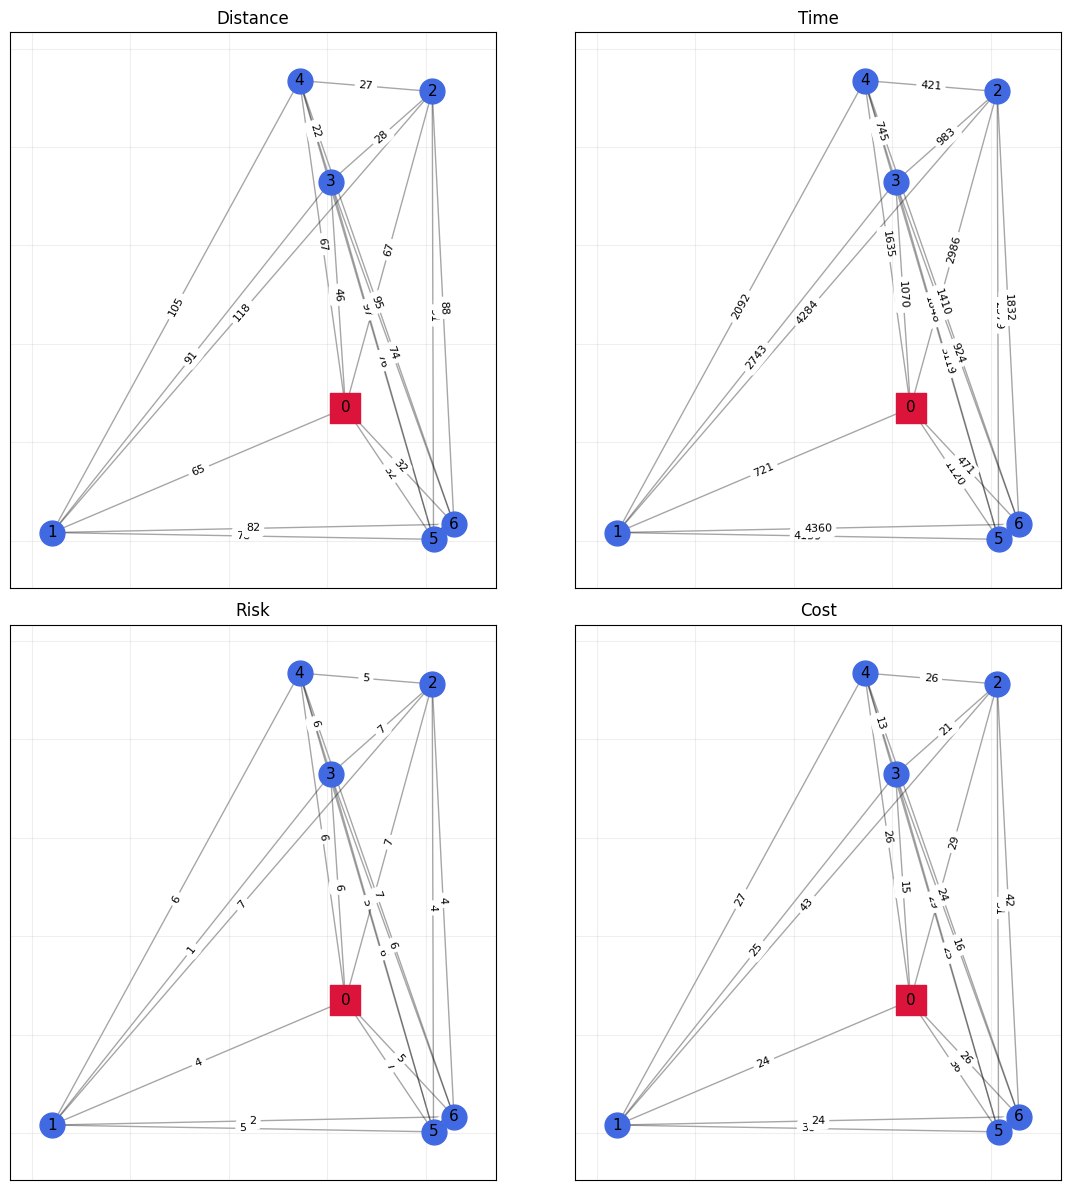

In [4]:
def draw_vrp_graph_networkx(coords, c_core, title="VRP graph",
                            cost_threshold=None,
                            show_weights=True, ax=None):
    coords = np.asarray(coords)
    c = np.asarray(c_core)
    n_nodes = coords.shape[0]

    G = nx.Graph()
    for i in range(n_nodes):
        G.add_node(i, pos=(coords[i,0], coords[i,1]))

    for i in range(n_nodes):
        for j in range(i+1, n_nodes):
            if cost_threshold is None or c[i,j] <= cost_threshold:
                G.add_edge(i, j, weight=int(c[i,j]))

    pos = {i: (coords[i,0], coords[i,1]) for i in range(n_nodes)}

    if ax is None:
        fig, ax = plt.subplots(figsize=(7,7))

    nx.draw_networkx_nodes(G, pos, nodelist=[0],
                           node_color="crimson", node_shape="s", node_size=450, ax=ax)
    nx.draw_networkx_nodes(G, pos,
                           nodelist=list(range(1, n_nodes)),
                           node_color="royalblue", node_shape="o", node_size=320, ax=ax)

    nx.draw_networkx_edges(G, pos, alpha=0.35, width=1.0, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=11, font_color="black", ax=ax)

    if show_weights:
        edge_labels = {(u,v): d["weight"] for u,v,d in G.edges(data=True)}
        nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8, ax=ax)

    ax.set_title(title)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.2)

fig, axes = plt.subplots(2, 2, figsize=(12, 12))

for ax, (name, matrix) in zip(axes.flatten(), instances.items()):
    draw_vrp_graph_networkx(
        coords,
        matrix,
        title=name,
        ax=ax
    )

plt.tight_layout()
plt.show()

## 2) Sets and notation


- Depot: node **0**
- Customers: $ C = \{1,\dots,n\} $
- Full node set:  
  $$
  V = \{0\} \cup C
  $$

### Binary variable

$$
x_{ij} = 1 \iff \text{a vehicle travels from node } i \text{ to node } j
$$

for all $ i,j \in V $, with $ i \ne j $.

### Interpretation

- If $ x_{ij} = 1 $, some vehicle uses arc $ i \to j $.
- The number of vehicles is controlled by the number of arcs leaving and entering the depot.

In [5]:
def build_sets(n_customers):
    depot = 0
    customers = list(range(1, n_customers + 1))
    V = [depot] + customers
    return depot, customers, V


depot, C, V = build_sets(n_customers)

print("Depot:", depot)
print("Customers:", C)
print("Node set V:", V)
print("Number of possible directed arcs (excluding self-loops):",
      len(V) * (len(V) - 1))

Depot: 0
Customers: [1, 2, 3, 4, 5, 6]
Node set V: [0, 1, 2, 3, 4, 5, 6]
Number of possible directed arcs (excluding self-loops): 42


## 3) Variable indexing: map $ x_{ij} $ into a single QUBO vector


A QUBO uses one large binary vector $ z $.

We map each decision variable $ x_{ij} $ (arc selection) to a unique index in that vector.

### Decision variables

$$
x_{ij} =
\begin{cases}
1 & \text{if a vehicle travels from node } i \text{ to node } j \\
0 & \text{otherwise}
\end{cases}
$$

for all $ i, j \in V $, with $ i \ne j $.

The total number of binary variables is simply:

$$
|V| (|V| - 1)
$$

which scales as $ O(n^2) $.

In [6]:
def variable_indexing(V):
    """
    Map each arc variable x_{ij}, i != j, to a unique QUBO index.
    """
    x_index = {}
    idx = 0

    for i in V:
        for j in V:
            if i != j:
                x_index[(i, j)] = idx
                idx += 1

    return x_index, idx


x_index, n_vars = variable_indexing(V)

print("Total binary variables:", n_vars)
print("Expected |V|*(|V|-1) =", len(V) * (len(V) - 1))

Total binary variables: 42
Expected |V|*(|V|-1) = 42


## 4) QUBO construction helpers


We construct an energy:
$$
H(z) = z^T Q z + \text{constant}
$$

We use helper functions to add:
- linear terms $a z_i$ (store as diagonal)
- quadratic terms $b z_i z_j$ (store in upper triangle)
- squared penalties of affine expressions $(\sum a_i z_i + c)^2$


In [7]:
def add_quadratic(Qmat, i, j, coeff):
    # Store in upper triangle
    if i <= j:
        Qmat[i, j] += coeff
    else:
        Qmat[j, i] += coeff


def add_linear(Qmat, i, coeff):
    # Linear coeff*z_i stored on diagonal
    Qmat[i, i] += coeff


def square_of_affine_to_qubo(Qmat, var_coeffs, constant, weight=1.0):
    # Adds weight*(sum_i a_i z_i + constant)^2
    # Expansion: weight*( z^T (a a^T) z + 2*constant*(a^T z) + constant^2 )
    # For binary z, keep all terms in QUBO form.

    items = list(var_coeffs.items())

    # Quadratic + diagonal from (a^T z)^2
    for p, (i, ai) in enumerate(items):
        add_linear(Qmat, i, weight * (ai * ai))  # ai^2 z_i
        for j, aj in items[p+1:]:
            add_quadratic(Qmat, i, j, weight * (2 * ai * aj))

    # Linear from 2*constant*(a^T z)
    for i, ai in items:
        add_linear(Qmat, i, weight * (2 * constant * ai))

    # Constant contribution
    return weight * (constant * constant)

## 5) Build the full QUBO (cost + penalties)

In the arc-based VRP formulation, the energy is:

$$
H(z) = \text{travel cost} + \text{penalties}
$$

### Decision variables

$$
x_{ij} = 1 \iff \text{arc } i \to j \text{ is used}
$$

for all $ i,j \in V, \; i \ne j $.

### Cost term

$$
\sum_{i \ne j} c_{ij} x_{ij}
$$

### Penalties

We enforce:

1. **Each customer has exactly one outgoing arc**
   $$
   \sum_{j \in V, j \ne i} x_{ij} = 1
   \quad \forall i \in C
   $$

2. **Each customer has exactly one incoming arc**
   $$
   \sum_{j \in V, j \ne i} x_{ji} = 1
   \quad \forall i \in C
   $$

3. **Exactly $K$ vehicles leave the depot**
   $$
   \sum_{j \in C} x_{0j} = K
   $$

4. **Exactly $K$ vehicles return to the depot**
   $$
   \sum_{i \in C} x_{i0} = K
   $$

5. **Subtour elimination**

The constraints above allow disconnected subtours — cycles among customers not connected to the depot. To eliminate them, we enforce that every non-empty subset $S$ of customers has at least one arc leaving it:

$$
\sum_{i \in S} \sum_{j \notin S} x_{ij} \geq 1, \quad \forall S \subset C, S \neq \emptyset
$$

This ensures connectivity to the depot (directly or via other customers). For $K>1$, this allows multiple routes while preventing isolated cycles.

All constraints are encoded as squared penalties.

In [8]:
# -------------------------
# Build sets
# -------------------------
def build_sets(n_customers):
    depot = 0
    customers = list(range(1, n_customers + 1))
    V = [depot] + customers
    return depot, customers, V


depot, C, V = build_sets(n_customers)

print("Depot:", depot)
print("Customers:", C)
print("Node set V:", V)
print("Number of possible directed arcs (excluding self-loops):",
      len(V) * (len(V) - 1))


# -------------------------
# QUBO builder (UPDATED)
# -------------------------
def build_qubo(c_core, K, lambdas=None):
    x_index, n_vars = variable_indexing(V)
    Qmat = np.zeros((n_vars, n_vars), dtype=float)
    const = 0.0

    # -------------------------
    # Adaptive lambdas (per instance)
    # -------------------------
    if lambdas is None:
        max_cost_hint = np.max(c_core) * len(c_core)
        lambdas = {
            "out_degree": 20 * max_cost_hint,
            "in_degree": 20 * max_cost_hint,
            "start": 20 * max_cost_hint,
            "end": 20 * max_cost_hint,
            "subtour": 5 * max_cost_hint
        }

    # -------------------------
    # 6.1 Travel cost (linear)
    # -------------------------
    for (i, j), idx in x_index.items():
        add_linear(Qmat, idx, float(c_core[i, j]))

    # -------------------------
    # 6.2 Out-degree = 1
    # -------------------------
    for i in C:
        var_coeffs = {
            x_index[(i, j)]: 1.0
            for j in V if j != i
        }
        const += square_of_affine_to_qubo(
            Qmat,
            var_coeffs,
            constant=-1.0,
            weight=lambdas["out_degree"]
        )

    # -------------------------
    # 6.3 In-degree = 1
    # -------------------------
    for i in C:
        var_coeffs = {
            x_index[(j, i)]: 1.0
            for j in V if j != i
        }
        const += square_of_affine_to_qubo(
            Qmat,
            var_coeffs,
            constant=-1.0,
            weight=lambdas["in_degree"]
        )

    # -------------------------
    # 6.4 Depot خروج = K
    # -------------------------
    var_coeffs = {
        x_index[(depot, j)]: 1.0
        for j in C
    }
    const += square_of_affine_to_qubo(
        Qmat,
        var_coeffs,
        constant=-K,
        weight=lambdas["start"]
    )

    # -------------------------
    # 6.5 Depot entrada = K
    # -------------------------
    var_coeffs = {
        x_index[(i, depot)]: 1.0
        for i in C
    }
    const += square_of_affine_to_qubo(
        Qmat,
        var_coeffs,
        constant=-K,
        weight=lambdas["end"]
    )

    # -------------------------
    # 6.6 Subtour elimination
    # -------------------------
    from itertools import combinations

    lambda_subtour = lambdas["subtour"]
    customers_list = list(C)
    n_cust = len(customers_list)

    for r in range(1, n_cust):
        for subset in combinations(customers_list, r):
            subset = set(subset)

            var_coeffs = {}
            for i in subset:
                for j in V:
                    if j != i and j not in subset:
                        if (i, j) in x_index:
                            var_coeffs[x_index[(i, j)]] = 1.0

            if var_coeffs:
                const += square_of_affine_to_qubo(
                    Qmat,
                    var_coeffs,
                    constant=-1.0,
                    weight=lambda_subtour
                )

    info = {
        "depot": depot,
        "customers": C,
        "V": V,
        "coords": coords,
        "c_core": c_core,
        "x_index": x_index,
        "n_vars": n_vars,
        "lambdas": lambdas,
        "K": K,
    }

    return Qmat, const, info


# -------------------------
# Build ALL QUBOs (NEW)
# -------------------------
instances = {
    "distance": dist_matrix,
    "time": time_matrix,
    "risk": risk_matrix,
    "cost": cost_matrix
}

qubo_models = {}

for name, matrix in instances.items():
    Qmat, const, info = build_qubo(matrix, K)

    qubo_models[name] = {
        "Q": Qmat,
        "const": const,
        "info": info
    }

    print(f"\n{name.upper()} QUBO")
    print("Variables:", info["n_vars"])
    print("Constant:", const)
    print("Max |Q| coeff:", np.max(np.abs(Qmat)))

Depot: 0
Customers: [1, 2, 3, 4, 5, 6]
Node set V: [0, 1, 2, 3, 4, 5, 6]
Number of possible directed arcs (excluding self-loops): 42

DISTANCE QUBO
Variables: 42
Constant: 586460.0
Max |Q| coeff: 194078.0

TIME QUBO
Variables: 42
Constant: 21669200.0
Max |Q| coeff: 7171729.0

RISK QUBO
Variables: 42
Constant: 34790.0
Max |Q| coeff: 11511.0

COST QUBO
Variables: 42
Constant: 213710.0
Max |Q| coeff: 70720.0


# 6) Exploring Solution


Find optimal solution by exhaustive search and check candidate solutions against it.

### Solve by Brute Force

#### Parallel

In [69]:
from itertools import product
from multiprocessing import Pool, cpu_count
from tqdm import tqdm

def solve_chunk(args):
    Q, const, fixed_bits, n = args
    
    k = len(fixed_bits)
    best_val = np.inf
    best_x_list = []
    
    for tail in product([0, 1], repeat=n - k):
        bits = fixed_bits + tail
        x = np.array(bits)
        val = x @ Q @ x + const
        
        if val < best_val - 1e-10:
            best_val = val
            best_x_list = [x]
        elif abs(val - best_val) < 1e-10:
            best_x_list.append(x)
    
    return best_val, best_x_list


def brute_force_parallel(Q, const, k=4):
    n = len(Q)
    
    prefixes = list(product([0, 1], repeat=k))
    args = [(Q, const, prefix, n) for prefix in prefixes]
    
    with Pool(cpu_count()) as pool:
        results = []
    
        for result in tqdm(pool.imap_unordered(solve_chunk, args),
						total=len(args),
						desc="Processing chunks"):
            results.append(result)
    
    # 🔥 Combinar resultados
    global_best = np.inf
    global_solutions = []
    
    for val, sols in results:
        if val < global_best - 1e-10:
            global_best = val
            global_solutions = sols
        elif abs(val - global_best) < 1e-10:
            global_solutions.extend(sols)
    
    return global_solutions, global_best

solutions = {}

for name, model in qubo_models.items():
    print(f"\nSolving QUBO for: {name.upper()}")

    Q = model["Q"]
    const = model["const"]

    opt_x_list, opt_val = brute_force_parallel(Q, const, 12)

    solutions[name] = {
        "opt_x_list": opt_x_list,
        "opt_val": opt_val
    }

    print(f"Optimal value: {opt_val}")
    print(f"Number of optimal solutions: {len(opt_x_list)}")

    for i, opt_x in enumerate(opt_x_list):
        print(f"Solution {i+1}: {opt_x}")


Solving QUBO for: DISTANCE


Processing chunks:   0%|          | 0/4096 [00:00<?, ?it/s]

#### Single-thread

In [12]:
from itertools import product
from tqdm import tqdm

def brute_force_qubo_all_fast(Q, const):
    n = len(Q)
    best_val = np.inf
    best_x_list = []

    x = np.zeros(n, dtype=np.float64)

    for bits in tqdm(product([0, 1], repeat=n),
                     total=1 << n,
                     desc="Brute force"):
        # atualizar x in-place
        x[:] = bits

        val = x @ Q @ x + const

        if val < best_val - 1e-10:
            best_val = val
            best_x_list = [x.copy()]
        elif abs(val - best_val) < 1e-10:
            best_x_list.append(x.copy())

    return best_x_list, best_val

solutions = {}

for name, model in qubo_models.items():
    print(f"\nSolving QUBO for: {name.upper()}")

    Q = model["Q"]
    const = model["const"]

    opt_x_list, opt_val = brute_force_qubo_all_fast(Q, const)

    solutions[name] = {
        "opt_x_list": opt_x_list,
        "opt_val": opt_val
    }

    print(f"Optimal value: {opt_val}")
    print(f"Number of optimal solutions: {len(opt_x_list)}")

    for i, opt_x in enumerate(opt_x_list):
        print(f"Solution {i+1}: {opt_x}")


Solving QUBO for: DISTANCE


Brute force: 100%|██████████| 1048576/1048576 [00:06<00:00, 157813.68it/s]


Optimal value: 15021.0
Number of optimal solutions: 2
Solution 1: [0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 0. 1. 0. 0.]
Solution 2: [1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 1. 0.]

Solving QUBO for: TIME


Brute force: 100%|██████████| 1048576/1048576 [00:07<00:00, 134470.98it/s]


Optimal value: 416547.0
Number of optimal solutions: 2
Solution 1: [0. 0. 1. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0.]
Solution 2: [1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 1.]

Solving QUBO for: RISK


Brute force: 100%|██████████| 1048576/1048576 [00:07<00:00, 136173.47it/s]


Optimal value: 898.0
Number of optimal solutions: 2
Solution 1: [0. 1. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 1. 0. 0.]
Solution 2: [1. 0. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1.]

Solving QUBO for: COST


Brute force: 100%|██████████| 1048576/1048576 [00:07<00:00, 143489.61it/s]

Optimal value: 5359.0
Number of optimal solutions: 2
Solution 1: [0. 0. 0. 1. 0. 0. 1. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0.]
Solution 2: [0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 1. 0. 0. 0.]


### Solver

In [9]:
import gurobipy as gp
from gurobipy import GRB

def solve_qubo(Q, const=0):
    n = len(Q)

    m = gp.Model()
    x = m.addVars(n, vtype=GRB.BINARY)

    obj = gp.quicksum(Q[i,j] * x[i] * x[j] for i in range(n) for j in range(n))
    m.setObjective(obj + const, GRB.MINIMIZE)

    m.optimize()

    sol = [int(x[i].x) for i in range(n)]
    return sol, m.objVal

solutions = {}

for name, model in qubo_models.items():
    print(f"\nSolving QUBO for: {name.upper()}")

    Q = model["Q"]
    const = model["const"]

    opt_x_list, opt_val = solve_qubo(Q, const)
    opt_x_list = [opt_x_list]

    solutions[name] = {
        "opt_x_list": opt_x_list,
        "opt_val": opt_val
    }

    print(f"Optimal value: {opt_val}")
    print(f"Number of optimal solutions: {len(opt_x_list)}")

    for i, opt_x in enumerate(opt_x_list):
        print(f"Solution {i+1}: {opt_x}")


Solving QUBO for: DISTANCE
Restricted license - for non-production use only - expires 2027-11-29
Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 10.0 (19045.2))

CPU model: Intel(R) Core(TM) i5-7300HQ CPU @ 2.50GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 4 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 0 rows, 42 columns and 0 nonzeros (Min)
Model fingerprint: 0xb00bad98
Model has 0 linear objective coefficients and an objective constant of 586460
Model has 552 quadratic objective terms
Variable types: 0 continuous, 42 integer (42 binary)
Coefficient statistics:
  Matrix range     [0e+00, 0e+00]
  Objective range  [0e+00, 0e+00]
  QObjective range [7e+04, 4e+05]
  Bounds range     [1e+00, 1e+00]
  RHS range        [0e+00, 0e+00]

Found heuristic solution: objective 586460.00000
Found heuristic solution: objective 161340.00000
Found heuristic solution: objective 161292.00000
Presolve time: 0.01s
Presolved: 510 rows, 552 colum

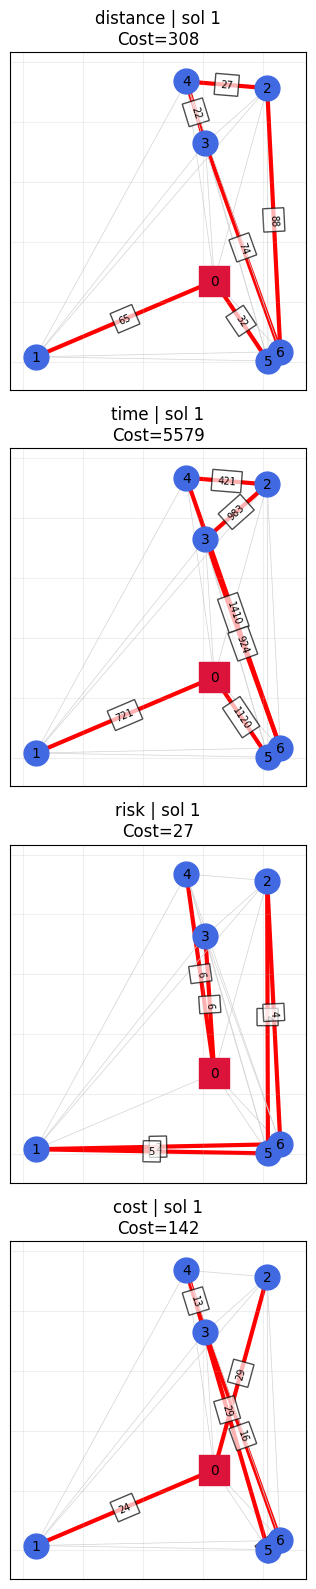

In [10]:
def visualize_route(opt_x, info, ax=None, title=""):
    """
    Visualiza a rota encontrada no grafo (agora com suporte a subplot)
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 7))

    # -------------------------
    # Converter solução
    # -------------------------
    x_dict = {}
    for (i, j), idx in info['x_index'].items():
        if opt_x[idx] == 1:
            x_dict[(i, j)] = 1

    custo_real = sum(info['c_core'][i, j] for (i, j) in x_dict)

    # -------------------------
    # Construir rotas
    # -------------------------
    next_node = {i: j for (i, j) in x_dict}
    visited = set()
    routes = []

    for start in next_node:
        if start in visited:
            continue

        route = [start]
        current = start

        while True:
            if current not in next_node:
                break  # caminho aberto (não deve acontecer, mas seguro)

            current = next_node[current]

            if current in route:
                route.append(current)  # fecha ciclo
                break

            route.append(current)

        visited.update(route)
        routes.append(route)

    # -------------------------
    # Grafo
    # -------------------------
    coords = info['coords']
    c_core = info['c_core']
    n_nodes = len(coords)

    G = nx.Graph()
    for i in range(n_nodes):
        G.add_node(i, pos=(coords[i, 0], coords[i, 1]))

    # todas arestas (cinza)
    for i in range(n_nodes):
        for j in range(i + 1, n_nodes):
            G.add_edge(i, j, weight=int(c_core[i, j]), color='lightgray', width=0.5)

    # solução (vermelho)
    for (i, j) in x_dict:
        if G.has_edge(i, j):
            G[i][j]['color'] = 'red'
            G[i][j]['width'] = 3
        else:
            G.add_edge(i, j, weight=int(c_core[i, j]), color='red', width=3)

    pos = {i: (coords[i, 0], coords[i, 1]) for i in range(n_nodes)}

    edges = G.edges()
    colors = [G[u][v]['color'] for u, v in edges]
    widths = [G[u][v]['width'] for u, v in edges]

    nx.draw_networkx_nodes(G, pos, nodelist=[0],
                           node_color="crimson", node_shape="s", node_size=450, ax=ax)
    nx.draw_networkx_nodes(G, pos,
                           nodelist=list(range(1, n_nodes)),
                           node_color="royalblue", node_shape="o", node_size=320, ax=ax)

    nx.draw_networkx_edges(G, pos, edge_color=colors, width=widths, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=10, ax=ax)

    # labels só da solução
    edge_labels = {(u, v): G[u][v]['weight']
                   for (u, v) in x_dict if G.has_edge(u, v)}

    nx.draw_networkx_edge_labels(
        G, pos,
        edge_labels=edge_labels,
        font_size=7,
        bbox=dict(facecolor='white', alpha=0.7),
        ax=ax
    )

    ax.set_title(f"{title}\nCost={custo_real}")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.2)

def plot_all_solutions_grid(solutions, qubo_models):
    instance_names = list(solutions.keys())

    # número máximo de soluções ótimas em qualquer instância
    max_solutions = max(len(solutions[name]["opt_x_list"]) for name in instance_names)

    n_rows = len(instance_names)
    n_cols = max_solutions

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 4*n_rows))

    # garantir que axes é 2D
    if n_rows == 1:
        axes = np.array([axes])
    if n_cols == 1:
        axes = axes.reshape(-1, 1)

    for i, name in enumerate(instance_names):
        opt_list = solutions[name]["opt_x_list"]
        info = qubo_models[name]["info"]

        for j in range(n_cols):
            ax = axes[i, j]

            if j < len(opt_list):
                visualize_route(
                    opt_list[j],
                    info,
                    ax=ax,
                    title=f"{name} | sol {j+1}"
                )
            else:
                ax.axis("off")

    plt.tight_layout()
    plt.show()

plot_all_solutions_grid(solutions, qubo_models)

## Check Solution

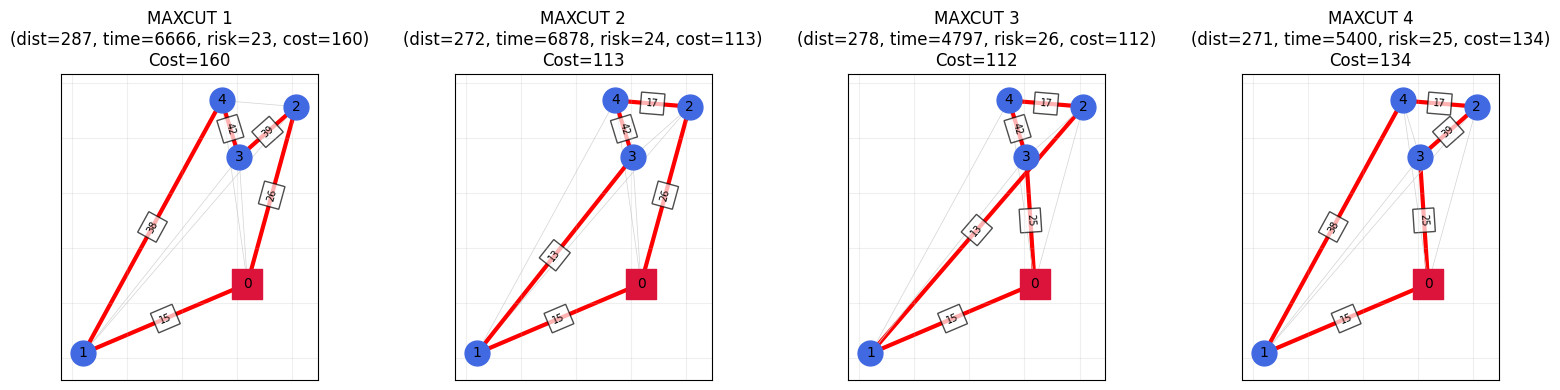

In [12]:
def compute_all_costs(x, x_index, instances):
    costs = {name: 0 for name in instances}

    for (i, j), idx in x_index.items():
        if x[idx]:
            for name, matrix in instances.items():
                costs[name] += matrix[i, j]

    return costs


import math

def plot_maxcut_solutions(x_list, info, instances, title_prefix="MAXCUT"):
    max_cols = 4
    n = len(x_list)

    n_cols = min(max_cols, n)
    n_rows = math.ceil(n / max_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 4*n_rows))

    # garantir formato 2D
    if n_rows == 1:
        axes = np.array([axes])
    if n_cols == 1:
        axes = axes.reshape(-1, 1)

    for idx_sol, x in enumerate(x_list):
        row = idx_sol // max_cols
        col = idx_sol % max_cols

        ax = axes[row, col]

        # -------------------------
        # calcular custos
        # -------------------------
        costs = compute_all_costs(
            x,
            info["x_index"],
            instances
        )

        cost_str = "(" + ", ".join([
            f"{k[:4]}={v}" for k, v in costs.items()
        ]) + ")"

        # -------------------------
        # plot
        # -------------------------
        visualize_route(
            x,
            info,
            ax=ax,
            title=f"{title_prefix} {idx_sol+1}\n{cost_str}"
        )

    # desligar eixos vazios
    total_plots = n_rows * n_cols
    for k in range(n, total_plots):
        row = k // max_cols
        col = k % max_cols
        axes[row, col].axis("off")

    plt.tight_layout()
    plt.show()


def plot_maxcut_matrix(Z, info, instances):
    z_list = [Z[i] for i in range(Z.shape[0])]
    plot_maxcut_solutions(z_list, info, instances)


def canonicalize_and_deduplicate(solutions, info):
    def canonicalize_route(route):
        core = route[1:-1]  # remove os zeros das pontas
        forward = tuple(core)
        backward = tuple(core[::-1])
        return min(forward, backward)
    
    def extract_route_from_x(x, info):
        """
        Reconstrói a rota no formato [0, ..., 0]
        usando x_index.
        """
        x_index = info["x_index"]

        # cria lista de arestas ativas
        edges = [(i, j) for (i, j), idx in x_index.items() if x[idx]]

        # constrói adjacência
        adj = {}
        for i, j in edges:
            adj.setdefault(i, []).append(j)
            adj.setdefault(j, []).append(i)

        # reconstrói ciclo começando do depot (0)
        route = [0]
        current = 0
        prev = None

        while True:
            neighbors = adj[current]
            next_node = neighbors[0] if neighbors[0] != prev else neighbors[1]

            if next_node == 0:
                route.append(0)
                break

            route.append(next_node)
            prev, current = current, next_node

        return route

    solutions = np.array(solutions, dtype=np.int8)

    # -------------------------
    # 1. remover gauge
    # -------------------------
    last_bit = solutions[:, -1]
    core = solutions[:, :-1].copy()

    flip_mask = last_bit == 1
    core[flip_mask] = 1 - core[flip_mask]

    # -------------------------
    # 2. remover duplicatas de rota
    # -------------------------
    seen = set()
    unique = []

    for x in core:
        route = extract_route_from_x(x, info)
        canonical = canonicalize_route(route)

        if canonical not in seen:
            seen.add(canonical)
            unique.append(x)

    return np.array(unique, dtype=np.int8)


list_of_solutions = [[0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0],
       [1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0],
       [0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1],
       [1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0],
       [0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0],
       [0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1],
       [1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1]]

list_of_solutions_unique = canonicalize_and_deduplicate(list_of_solutions, info)
plot_maxcut_solutions(list_of_solutions_unique, info, instances)

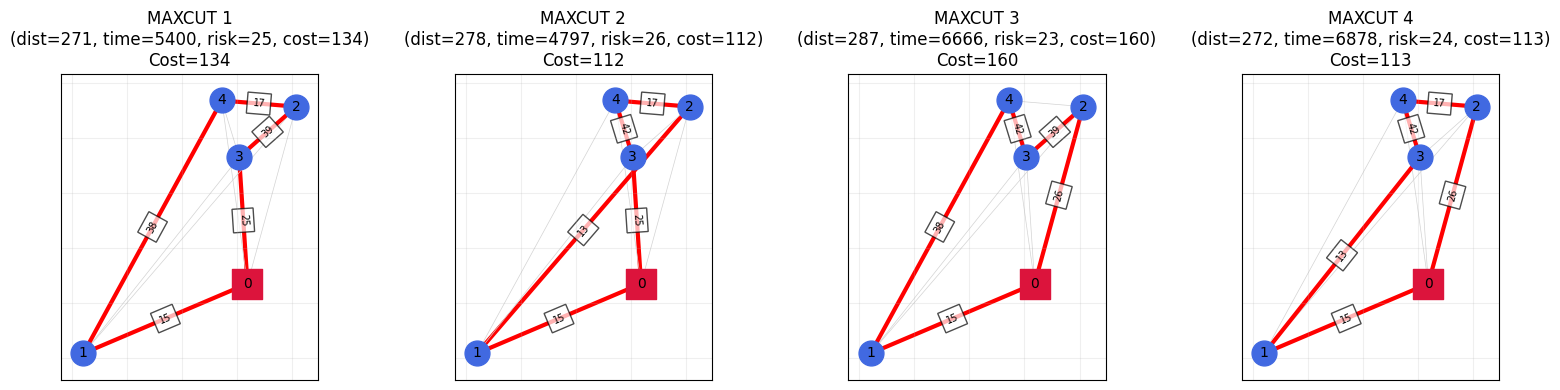

In [13]:
list_of_solutions = [[1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1],
       [0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0],
       [0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1]]

list_of_solutions_unique = canonicalize_and_deduplicate(list_of_solutions, info)
plot_maxcut_solutions(list_of_solutions_unique, info, instances)

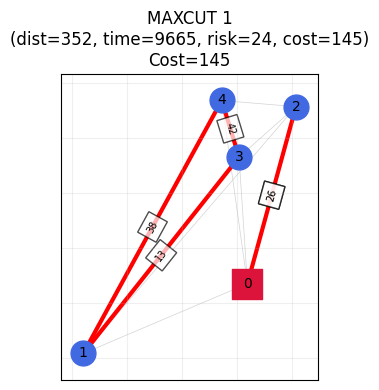

In [23]:
list_of_solutions = [[0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0]]

list_of_solutions_unique = canonicalize_and_deduplicate(list_of_solutions, info)
plot_maxcut_solutions(list_of_solutions_unique, info, instances)

# 7) QUBO to Max-Cut Reduction

We convert a QUBO problem

$$
\max_{x \in \{0,1\}^n} x^T Q x
$$

into an equivalent **Max-Cut** problem on a graph with **$n+1$ vertices**. This transformation follows the construction proposed by Bhattacharyya *et al.* (2025), where an auxiliary vertex is introduced to eliminate the linear terms that appear when mapping binary variables $\{0,1\}$ into Ising spins $\{-1,1\}$.

The adjacency matrix $A$ of the Max-Cut graph is constructed from the QUBO matrix $Q$ as

$$
A_{i,j} = -Q_{i,j}, \quad
A_{n,i} = \sum_{j=0}^{n-1} Q_{i,j}, \quad
A_{n,n} = 0.
$$

Solving the Max-Cut problem on this graph is energetically equivalent to solving the original QUBO. The extra vertex (the last one) is an auxiliary node introduced by the reduction and plays a special role in warm-start QAOA methods.


In [33]:
def normalize_qubo(Q):
    Q = np.array(Q, dtype=float)
    max_abs = np.max(np.abs(Q))
    if max_abs > 0:
        Q = Q / max_abs
    return Q

def qubo_to_maxcut_matrix(Q):
    """
    Convert QUBO matrix Q (n x n) to Max-Cut adjacency matrix A (n+1 x n+1)
    following the paper mapping.
    """
    n = Q.shape[0]
    A = np.zeros((n+1, n+1))

    # Edges between original variables
    for i in range(n):
        for j in range(i+1, n):
            A[i, j] = A[j, i] = -Q[i, j]

    # Edges to auxiliary node
    row_sums = Q.sum(axis=1)
    for i in range(n):
        A[i, n] = A[n, i] = row_sums[i]

    np.fill_diagonal(A, 0)
    return A

maxcut_models = {}

for name, model in qubo_models.items():
    print(f"\nConverting QUBO → MAXCUT: {name.upper()}")

    Q = model["Q"]

    # 1. simetrizar
    Q_sym = (Q + Q.T) / 2.0

    # 2. transformar em problema de maximização
    Qmax = -Q_sym

    # 3. normalizar
    Q_norm = normalize_qubo(Qmax)

    # 4. converter para MAXCUT
    A = qubo_to_maxcut_matrix(Q_norm)

    # salvar tudo
    maxcut_models[name] = {
        "Q_sym": Q_sym,
        "Qmax": Qmax,
        "Q_norm": Q_norm,
        "A": A
    }

    print(f"A shape: {A.shape}")


Converting QUBO → MAXCUT: DISTANCE
A shape: (43, 43)

Converting QUBO → MAXCUT: TIME
A shape: (43, 43)

Converting QUBO → MAXCUT: RISK
A shape: (43, 43)

Converting QUBO → MAXCUT: COST
A shape: (43, 43)


This cell converts the adjacency matrix we created earlier to JSON format.

In [34]:
import json, os

def adjacency_matrix_to_json(A, filename="graph.json"):
    """
    Converts a weighted adjacency matrix to JSON-compatible format.

    Parameters:
    -----------
    A : list of list or np.ndarray
        n x n adjacency matrix, where A[i][j] is the weight of edge (i, j).
        If A[i][j] = 0, no edge is created (unless zero weights are valid).
        Matrix is assumed symmetric for undirected graphs.
    filename : str
        Output file name.
    """
    n = len(A)
    
    # Create list of nodes
    nodes = [{"id": i} for i in range(n)]
    
    # Create list of edges (links)
    links = []
    for i in range(n):
        # For undirected graphs, only traverse j > i to avoid duplication
        for j in range(i + 1, n):
            weight = A[i][j]
            # If you want to include edges with weight 0, remove the condition below
            if weight != 0:
                links.append({
                    "weight": float(weight),
                    "source": i,
                    "target": j
                })
    
    # Build final dictionary
    graph_data = {
        "directed": False,
        "multigraph": False,
        "graph": {},
        "nodes": nodes,
        "links": links
    }
    
    os.makedirs(os.path.dirname(filename), exist_ok=True)
    
    # Save to JSON file
    with open(filename, 'w', encoding='utf-8') as f:
        json.dump(graph_data, f, indent=2, ensure_ascii=False)
    
    print(f"File saved as {filename}")
    return graph_data
    
base_path = "../qamoo/data/problems"

for idx, (name, model) in enumerate(maxcut_models.items()):
    print(f"\nSaving {name} as problem_graph_{idx}.json")

    A = model["A"]

    # número de qubits = n + 1 (por causa do nó auxiliar)
    n_qubits = A.shape[0]

    filename = (
        f"{base_path}/"
        f"{n_qubits}q/"
        f"problem_set_{n_qubits}q_10s_3o_0/"
        f"problem_graph_{idx}.json"
    )

    adjacency_matrix_to_json(A, filename)


Saving distance as problem_graph_0.json
File saved as ../qamoo/data/problems/43q/problem_set_43q_10s_3o_0/problem_graph_0.json

Saving time as problem_graph_1.json
File saved as ../qamoo/data/problems/43q/problem_set_43q_10s_3o_0/problem_graph_1.json

Saving risk as problem_graph_2.json
File saved as ../qamoo/data/problems/43q/problem_set_43q_10s_3o_0/problem_graph_2.json

Saving cost as problem_graph_3.json
File saved as ../qamoo/data/problems/43q/problem_set_43q_10s_3o_0/problem_graph_3.json
